# Recipe — convergence occupancy, within patient

**One question:** in my paired tumour / matched-normal single-cell cohort, is a larger fraction of the *malignant* cells than of the *same patient's normal* cells nearest to the **core** of the convergence region — the placental cytotrophoblast and the megakaryocyte — in the cancer-blind coordinate system of Spiro (2026)?

**Inputs:** an AnnData of malignant and matched-normal epithelial cells (counts or log-normalized, HGNC symbols in `var_names`) with a patient and an arm label per cell.

**Outputs:** per-patient core occupancy in both arms, the paired Wilcoxon and sign tests across patients, and the paper's two controls (shape-only, complexity-matched).

**This notebook runs offline on a synthetic cohort** generated from the bundled normal-cell reference. The effect in the first cohort is put there by construction: the recipe shows the mechanics and the statistics, **not** a result about cancer. For real data, replace the cell that builds `adata` and switch to `calibration="single_cell_scaled"` (see [`docs/CONVERGENCE.md`](../docs/CONVERGENCE.md)); what the paper does and does not support is in [`docs/SCOPE.md`](../docs/SCOPE.md).

In [1]:
import numpy as np
import pandas as pd
import anndata
import matplotlib.pyplot as plt

import perceptome as pct
from perceptome import convergence as cv

print("perceptome", pct.__version__)
print("\nRegions of normal cell-state space (nearest normal cell type of a cell):")
for name in ("anchor", "core", "neighbourhood", "region"):
    members = cv.region_members(name)
    print(f"  {name:14s} {len(members):2d} cell types, chance {100 * len(members) / 152:5.2f}%   "
          f"{', '.join(members[:3])}{' ...' if len(members) > 3 else ''}")

perceptome 0.2.2

Regions of normal cell-state space (nearest normal cell type of a cell):
  anchor          1 cell types, chance  0.66%   cytotrophoblasts
  core            2 cell types, chance  1.32%   cytotrophoblasts, megakaryocytes
  neighbourhood   4 cell types, chance  2.63%   cytotrophoblasts, megakaryocytes, gastric progenitor cells ...
  region         14 cell types, chance  9.21%   cytotrophoblasts, megakaryocytes, gastric progenitor cells ...


## 1. A synthetic paired cohort

Each cell gets a 44-module profile that follows the reference profile of one normal cell type (plus noise), spread over the catalog's genes and padded with filler genes so that quality control (≥ 1,000 detected genes) has something to count. Every patient has a tumour arm and a matched-normal arm of the same tissue (colon epithelium). A cell of either arm is core-like with a patient-specific probability:

| Patients | Matched normal | Tumour | What it illustrates |
|---|---|---|---|
| P01–P10 | 4% core-like | 4% + effect (12–30 points) | an effect carried by every patient |
| P11 | 4% | 4% | a patient without it |
| P12 | 4% | 0% | a patient with the reverse |
| P13 | 12 normal cells | — | too few cells to enter the test (floor: 20 per arm) |

In [2]:
R = pct.load_hpa_perceptivity()["R"].astype(float)      # 154 normal cell types x 44 modules
catalog = pct.load_catalog()["modules"]
modules_of = {}
for module, entry in catalog.items():
    for gene in entry["core_genes"]:
        modules_of.setdefault(gene, []).append(module)
panel = sorted(modules_of)
N_FILLER = 2500


def cell_profile(cell_type, rng, noise=0.15):
    x = np.array([np.mean([R.loc[cell_type, m] for m in modules_of[g]]) for g in panel])
    filler = rng.lognormal(0.5, 0.8, N_FILLER) * (rng.random(N_FILLER) < 0.7)
    return np.clip(np.concatenate([x + rng.normal(0, noise, len(x)), filler]), 0, None)


def make_cohort(effects, seed, normal_core=0.04, tissue="colonocytes",
                core_types=("cytotrophoblasts", "megakaryocytes"), floor_demo=True):
    """Per patient: a matched-normal and a tumour arm; `effects` = tumour minus normal core-like probability.
    With `floor_demo` the last patient gets only 12 normal cells (below the 20-cell floor)."""
    rng = np.random.default_rng(seed)
    rows, meta = [], []
    for i, effect in enumerate(effects, 1):
        for arm, p_core in (("normal", normal_core), ("tumour", max(normal_core + effect, 0.0))):
            n = 12 if (floor_demo and i == len(effects) and arm == "normal") else int(rng.integers(40, 60))
            for _ in range(n):
                cell_type = rng.choice(core_types, p=[0.6, 0.4]) if rng.random() < p_core else tissue
                rows.append(cell_profile(cell_type, rng))
                meta.append((f"P{i:02d}", arm, cell_type))
    obs = pd.DataFrame(meta, columns=["patient", "arm", "truth"], index=[f"c{i}" for i in range(len(rows))])
    var = pd.DataFrame(index=panel + [f"FILL{i}" for i in range(N_FILLER)])
    return anndata.AnnData(X=np.array(rows, dtype=np.float32), obs=obs, var=var)


# P01-P10 carry the effect; P11 has none; P12 the reverse; P13 has only 12 normal cells
effects = [0.25, 0.20, 0.30, 0.15, 0.22, 0.18, 0.28, 0.12, 0.24, 0.20, 0.0, -0.04, 0.20]
adata = make_cohort(effects, seed=1)
print(adata)
print(adata.obs.groupby(["patient", "arm"]).size().unstack().T.to_string())

AnnData object with n_obs × n_vars = 1235 × 2706
    obs: 'patient', 'arm', 'truth'
    layers: None (.X)
patient  P01  P02  P03  P04  P05  P06  P07  P08  P09  P10  P11  P12  P13
arm                                                                     
normal    49   48   51   58   48   52   40   50   57   41   49   42   12
tumour    50   52   58   48   55   56   50   40   44   45   43   53   44


## 2. Place every cell in the normal-cell space

`assign_cells` is the paper's per-cell pipeline: quality control, scoring of the 44 modules, standardization against a reference calibration, projection through the fixed 44 × 9 loadings, and assignment to the nearest of the **152 candidate normal cell types** by cosine (erythrocyte and platelet are removed from the pool *before* the assignment).

The calibration must match the scale of the data. These synthetic cells sit on the pseudobulk scale of the bundled reference, so `calibration="pseudobulk"` is the right one here. **Real per-cell data need `single_cell_scaled`**, which is not bundled — build it from the HPA table with `scripts/13_build_single_cell_calibration.py`. Under the pseudobulk calibration real tumour cells collapse onto low-complexity targets (Notes S-B, S-H), and `perceptome` warns when it sees that scale mismatch.

In [3]:
result = cv.assign_cells(adata, calibration="pseudobulk")
assignment = result["assignment"]
print("QC:", result["qc"])
print()
print(assignment.head().round(3).to_string())

QC: {'n_input': 1235, 'n_pass': 1235, 'min_genes': 1000, 'median_genes_input': 1956.0, 'normalized': False}

        nearest  cosine first_choice  displaced
c0  colonocytes   0.996  colonocytes      False
c1  colonocytes   0.999  colonocytes      False
c2  colonocytes   0.997  colonocytes      False
c3  colonocytes   0.998  colonocytes      False
c4  colonocytes   0.999  colonocytes      False


`nearest` is the assigned normal cell type and `cosine` its similarity to the cell; `first_choice` is the nearest of all 154 types before the quarantine, and `displaced` marks cells whose first choice was a quarantined type (erythrocyte, platelet) and who were reassigned to their best surviving neighbour. How the cells of each arm are distributed:

In [4]:
# Where do the cells of each arm land? (all patients pooled)
arm = adata.obs["arm"].reindex(assignment.index)
for name in ("normal", "tumour"):
    occ = cv.region_occupancy(assignment[arm == name])
    print(f"{name} arm, {int((arm == name).sum())} cells")
    print(occ.round(2).to_string(), "\n")

normal arm, 597 cells
                k  occupancy_pct  chance_pct  fold_over_chance
region                                                        
anchor          1           1.84        0.66               2.8
core            2           3.69        1.32               2.8
neighbourhood   4           3.69        2.63               1.4
region         14           3.69        9.21               0.4 

tumour arm, 638 cells
                k  occupancy_pct  chance_pct  fold_over_chance
region                                                        
anchor          1          14.42        0.66             21.92
core            2          23.82        1.32             18.11
neighbourhood   4          23.82        2.63              9.05
region         14          23.82        9.21              2.59 



The wider regions add nothing to the core here only because the synthetic cells come from two sources — core-like types and colonocytes. In real cohorts the four-cell neighbourhood and the 14-cell region fill up too (the paper's pooled cancers: 23.9% in the core, 41.9% in the neighbourhood, 76.9% in the region).

## 3. The within-patient test

For each patient the core fraction of the malignant arm is set against that patient's matched-normal arm (≥ 20 cells in each); the patients are then compared by a paired Wilcoxon test and a sign test. **The unit of replication is the patient, not the cell** — pooling cells would count thousands of correlated observations as independent.

In [5]:
test = pct.within_patient_occupancy(
    assignment, adata.obs["patient"], adata.obs["arm"], malignant="tumour", normal="normal")

pp = test["per_patient"]
table = pd.DataFrame({
    "cells (tumour / normal)": pp["n_malignant"].astype(int).astype(str) + " / " + pp["n_normal"].astype(int).astype(str),
    "tumour core %": (100 * pp["malignant"]).round(1),
    "normal core %": (100 * pp["normal"]).round(1),
    "difference (points)": (100 * pp["delta"]).round(1),
})
print(table.to_string())

left_out = sorted(set(adata.obs["patient"]) - set(pp.index))
print(f"\nleft out by the 20-cell floor: {left_out}")
print(f"{test['n_deeper']} of {test['n_patients']} patients higher in the malignant arm, {test['n_lower']} lower, {test['n_tied']} tied")
print(f"median core fraction: {100 * test['median_normal']:.1f}% normal -> {100 * test['median_malignant']:.1f}% malignant"
      f"  (median difference {100 * test['median_delta']:+.1f} points)")
print(f"paired Wilcoxon, two-sided:  P = {test['wilcoxon_two_sided']:.4f}")
print(f"sign test, one-sided:        P = {test['sign_test_one_sided']:.4f}")

        cells (tumour / normal)  tumour core %  normal core %  difference (points)
patient                                                                           
P01                     50 / 49           40.0            0.0                 40.0
P02                     52 / 48           38.5            4.2                 34.3
P03                     58 / 51           29.3            5.9                 23.4
P04                     48 / 58           20.8            6.9                 13.9
P05                     55 / 48           27.3            0.0                 27.3
P06                     56 / 52           23.2            1.9                 21.3
P07                     50 / 40           26.0            0.0                 26.0
P08                     40 / 50           12.5            4.0                  8.5
P09                     44 / 57           34.1            5.3                 28.8
P10                     45 / 41           24.4            4.9                 19.6
P11 

The paper reports the paired Wilcoxon test **two-sided** and the sign test **one-sided** (10 of 10 patients: P = 2/1024 = 0.002; 9 of 10: sign test P = 0.011; 15 of 22: 0.07); `within_patient_occupancy` returns both sidednesses of both tests. It also reports differences in **percentage points** — the fold change is inflated by a small normal denominator.

A test that cannot say no is not a test, so here is the same generator with **no effect** in any patient:

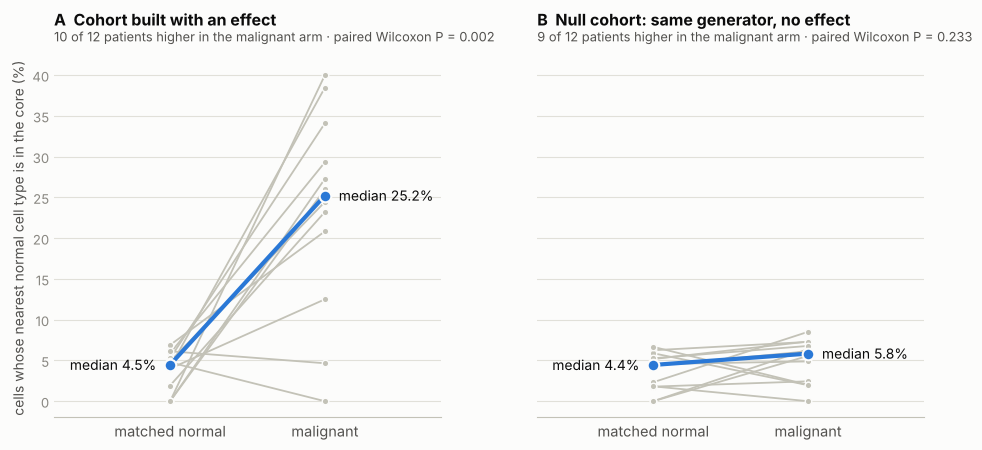

null cohort: 9 of 12 patients higher; Wilcoxon P = 0.23, sign test (one-sided) P = 0.07


In [6]:
null = make_cohort([0.0] * 13, seed=3)
null_assignment = cv.assign_cells(null, calibration="pseudobulk")["assignment"]
null_test = pct.within_patient_occupancy(
    null_assignment, null.obs["patient"], null.obs["arm"], malignant="tumour", normal="normal")

INK, INK2, MUTED, GRID, CONTEXT, ACCENT, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#2a78d6", "#fcfcfb"


def slope_panel(ax, res, title):
    pp = res["per_patient"]
    for _, r in pp.iterrows():
        ax.plot([0, 1], [100 * r["normal"], 100 * r["malignant"]], color=CONTEXT, lw=1.3, zorder=2)
        ax.scatter([0, 1], [100 * r["normal"], 100 * r["malignant"]], s=22, color=CONTEXT, edgecolor=SURFACE, linewidth=1, zorder=3)
    mn, mm = 100 * res["median_normal"], 100 * res["median_malignant"]
    ax.plot([0, 1], [mn, mm], color=ACCENT, lw=3, zorder=4)
    ax.scatter([0, 1], [mn, mm], s=70, color=ACCENT, edgecolor=SURFACE, linewidth=1.5, zorder=5)
    ax.annotate(f"median {mn:.1f}%", (0, mn), xytext=(-10, 0), textcoords="offset points", ha="right", va="center", fontsize=10, color=INK)
    ax.annotate(f"median {mm:.1f}%", (1, mm), xytext=(10, 0), textcoords="offset points", ha="left", va="center", fontsize=10, color=INK)
    ax.set_xlim(-0.75, 1.75)
    ax.set_xticks([0, 1], ["matched normal", "malignant"], color=INK2, fontsize=10.5)
    ax.set_title(title, loc="left", fontsize=11.5, fontweight="bold", color=INK, pad=24)
    ax.text(0, 1.04, f"{res['n_deeper']} of {res['n_patients']} patients higher in the malignant arm · paired Wilcoxon P = {res['wilcoxon_two_sided']:.3f}",
            transform=ax.transAxes, fontsize=9.3, color=INK2, va="bottom")
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.8, zorder=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(CONTEXT)
    ax.tick_params(axis="y", colors=MUTED, length=0, labelsize=9.5)
    ax.tick_params(axis="x", length=0)


fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.6), sharey=True, facecolor=SURFACE)
slope_panel(axes[0], test, "A  Cohort built with an effect")
slope_panel(axes[1], null_test, "B  Null cohort: same generator, no effect")
axes[0].set_ylabel("cells whose nearest normal cell type is in the core (%)", color=INK2, fontsize=10)
fig.tight_layout()
plt.show()
print(f"null cohort: {null_test['n_deeper']} of {null_test['n_patients']} patients higher; "
      f"Wilcoxon P = {null_test['wilcoxon_two_sided']:.2f}, sign test (one-sided) P = {null_test['sign_test_one_sided']:.2f}")

Chance alone can put 9 of 12 patients on one side (one-sided sign-test P ≈ 0.07), which is why the verdict rests on the test across patients and not on a count; with no effect the Wilcoxon test stays far from significance.

## 4. The paper's two controls

- **Shape-only** (`shape_only=True`): each cell's own mean over the 44 modules is subtracted — in the reference and in the cells alike, before the reference standardization — so only the *pattern* of module activity can place a cell, not its overall level. The paper's colorectal +10.5 points, lung +12.1 and gastric +3.4 are shape-only values.
- **Complexity matching** (`match_complexity=True`, with `n_genes`): each patient's malignant cells are resampled to the normal arm's distribution of detected genes. Low-complexity cells map to low-complexity targets, so a depth difference between the arms can masquerade as convergence; in the paper's colorectal data the matched comparison keeps about 80% of the effect. These synthetic arms have the same depth by construction, so matching should change little. Likewise, synthetic cells that follow reference profiles carry no overall-level component to remove, so the shape-only run reproduces the raw one; in real tumour data most of the raw contraction is magnitude, and the shape-only values are the smaller, real convergence in the pattern of module activity.

In [7]:
patient, arm_all = adata.obs["patient"], adata.obs["arm"]
shape_assignment = cv.assign_cells(adata, calibration="pseudobulk", shape_only=True)["assignment"]
shape_test = pct.within_patient_occupancy(shape_assignment, patient, arm_all, malignant="tumour", normal="normal")

matched_test = pct.within_patient_occupancy(                      # detected genes per cell come with the assignment
    assignment, patient, arm_all, malignant="tumour", normal="normal",
    n_genes=result["n_genes"], match_complexity=True)

controls = pd.DataFrame({
    "mean difference (points)": [100 * test["mean_delta"], 100 * shape_test["mean_delta"], 100 * matched_test["matched_delta"]],
    "patients higher": [f"{r['n_deeper']} of {r['n_patients']}" for r in (test, shape_test, matched_test)],
}, index=["raw", "shape-only", "complexity-matched"]).round(1)
print(controls.to_string())

                    mean difference (points) patients higher
raw                                     19.7        10 of 12
shape-only                              19.7        10 of 12
complexity-matched                      18.4        10 of 12


## 5. Pooling cohorts

Patients of several datasets are not exchangeable, and pooling them in one sign test can manufacture a Simpson's-paradox artifact. The paper's control (Note S-D) is a mixed model of the per-patient malignant-minus-normal difference with a **dataset random intercept**; `pct.pooled_within_patient` fits it (REML, Wald z, one-sided P for a deepening). Here a second synthetic dataset with a different baseline and smaller effects is pooled with the first:

In [8]:
effects_b = [0.15, 0.10, 0.18, 0.12, 0.08, 0.14, 0.05, 0.11]
adata_b = make_cohort(effects_b, seed=2, normal_core=0.08, floor_demo=False)
assignment_b = cv.assign_cells(adata_b, calibration="pseudobulk")["assignment"]
test_b = pct.within_patient_occupancy(
    assignment_b, adata_b.obs["patient"], adata_b.obs["arm"], malignant="tumour", normal="normal")

pooled = pct.pooled_within_patient({"dataset A": test["per_patient"], "dataset B": test_b["per_patient"]})
print(pooled["per_dataset"].round(1).to_string())
print(f"\nfixed deepening {pooled['estimate_points']:+.1f} points (SE {pooled['se_points']:.1f}), "
      f"z = {pooled['z']:.1f}, one-sided P = {pooled['p_one_sided']:.1g}")
print(f"variance between datasets {pooled['sigma2_dataset']:.5f}, between patients within a dataset {pooled['sigma2_residual']:.5f}")

           n_patients  n_deeper  mean_delta_points
dataset                                           
dataset A          12        10               19.7
dataset B           8         8               12.1

fixed deepening +16.3 points (SE 3.8), z = 4.3, one-sided P = 1e-05
variance between datasets 0.00158, between patients within a dataset 0.01307


Two datasets cannot support a random-effect estimate — the paper's own four (two of them colorectal) are already coarse, and the one-sided P does not propagate the uncertainty of the variance estimate. The model is the control the paper uses, not a licence to pool few datasets.

## 6. Set the result beside the paper's cohorts

`pct.convergence.published_within_patient()` carries the paper's cohort-level results (the effect sizes of the *real* datasets, which this synthetic cohort is not meant to resemble):

In [9]:
published = cv.published_within_patient()
cols = ["tissue", "n_patients", "n_deeper", "normal_pct", "malignant_pct", "shape_only_delta_points"]
print(published.loc[["colorectal_pelka", "kidney_ccrcc", "liver_hcc_sun", "gastric_gse150290", "lung_gse131907",
                     "prostate_census"], cols].to_string())
print("\npooled over four datasets (colorectal x2, kidney, liver):",
      int(published.loc["pooled_four_datasets", "n_deeper"]), "of", int(published.loc["pooled_four_datasets", "n_patients"]), "patients")

                     tissue  n_patients  n_deeper  normal_pct  malignant_pct  shape_only_delta_points
id                                                                                                   
colorectal_pelka      colon        46.0      43.0         3.2           18.9                     10.5
kidney_ccrcc         kidney         7.0       6.0         5.3           11.5                      NaN
liver_hcc_sun         liver         8.0       5.0        10.9           19.4                      NaN
gastric_gse150290   stomach        22.0      18.0         8.8           14.2                      3.4
lung_gse131907         lung        10.0      10.0        23.4           39.0                     12.1
prostate_census    prostate        15.0       7.0        15.0            NaN                      NaN

pooled over four datasets (colorectal x2, kidney, liver): 77 of 86 patients


## On real data

- **Calibration.** Per-cell data need `single_cell_scaled`; check that `pct.load_calibration("single_cell_scaled")` loads (it is built by `scripts/13_build_single_cell_calibration.py` and accepted only if it reproduces Table S7 of the paper).
- **Malignant-cell purity.** A tumour arm that is mostly normal-adjacent epithelium is diluted to the normal baseline — the Census lung "tumour" arm was about 9% annotated-malignant, which produced the retracted "no deepening in lung". Use author-annotated malignant compartments.
- **The right comparator.** Compare with the epithelium the cancer arises from (colorectal cancer: the crypt base), not with the tissue at large.
- **Do not rank cancers** by convergence fraction: the order moves with malignant-label quality and residual platform effects.
- **Pooling across datasets** with `pct.pooled_within_patient` (a dataset random intercept, section 5), not with one sign test over all patients.
- **Beyond occupancy:** how malignant and normal occupants of the state differ module by module (`pct.occupant_contrast`) and how tightly cancers contract relative to their origins (`pct.contraction`) are in [`docs/CONVERGENCE.md`](../docs/CONVERGENCE.md).
- **What a positive result is.** An increase of occupancy of a pre-existing region of normal cell-state space — a convergent endpoint across origins, not a measured trajectory and not a proven attractor.

Full guide: [`docs/CONVERGENCE.md`](../docs/CONVERGENCE.md) · scope and retractions: [`docs/SCOPE.md`](../docs/SCOPE.md) · paper-to-code map: [`docs/PAPER_MAP.md`](../docs/PAPER_MAP.md).